## Mechanical validity


In [1]:
ROOT = "../outputs/results"
import pandas as pd
from results_loader import MODELS, load_all, task_thresholds, asr_found, intent_hit
import paper_tables as pt
asr2, intent2 = load_all(ROOT)
thr2 = task_thresholds(asr2, intent2)
print("m-valid UTMOS thresholds per task:", {t: round(v, 3) for t, v in thr2.items()})

METHODS_TAB = ["GATAS", "GATAS_llm", "Waveform", "SMACK_untargeted", "SMACK", "ALIF", "PGD"]
rows = []
for task, data, found in (("ASR", asr2, asr_found), ("Intent", intent2, intent_hit)):
    for model in MODELS:
        for m in METHODS_TAB:
            rs = data[model].get(m)
            if rs:
                f = [r for r in rs if found(r)]
                k = sum(r["utmos"] >= thr2[task] for r in f)
                rows.append({"task": task, "model": model, "method": m, "n": len(rs), "found": len(f), "m_valid": k,
                             "m_valid_of_found_%": 100 * k / len(f) if f else float("nan")})
frame = pd.DataFrame(rows)
frame.round(3).to_csv("_tables/rq3_values.csv", index=False)
display(frame.round(1))

def validity_cell(task, model, m):
    r = frame[(frame.task == task) & (frame.model == model) & (frame.method == m)]
    return f"{r['m_valid_of_found_%'].iloc[0]:.1f} ({r.m_valid.iloc[0]}/{r.found.iloc[0]})" if len(r) and r.found.iloc[0] else "--"

rows = []
for m in METHODS_TAB:
    cells = [validity_cell(task, model, m) for model in MODELS for task in ("ASR", "Intent")]
    rows.append(f"{pt.TEX_NAME[m]} & " + " & ".join(cells) + r" \\")
tex = "\n".join([
    r"\begin{table*}[t]",
    r"\caption{Validity (RQ\textsubscript{3}). Share of m-valid test cases among the found ones (ASR) / target hits (intent), counts in parentheses.}",
    r"\label{tab:validity}", r"\centering", r"\footnotesize", r"\adjustbox{max width=\textwidth}{%",
    r"\begin{tabular}{lcccc}\toprule",
    r" & \multicolumn{2}{c}{Whisper-tiny} & \multicolumn{2}{c}{wav2vec2-large} \\",
    r"\cmidrule(lr){2-3}\cmidrule(lr){4-5}",
    r" & ASR [\%] & Intent [\%] & ASR [\%] & Intent [\%] \\ \midrule",
    *rows, r"\bottomrule", r"\end{tabular}}", r"\end{table*}"])
print(tex)
import os; os.makedirs("_tables", exist_ok=True); open("_tables/rq3.tex", "w").write(tex + "\n")


m-valid UTMOS thresholds per task: {'ASR': 4.262, 'Intent': 4.031}


/home/weissl/Projects/GATAS/analysis/results_loader.py:32: UserWarning: No PGD results for harvard / wav2vec2-large in ../outputs/results
  warnings.warn(f"No {method} results for {dataset} / {asr_model} in {results_root}")
/home/weissl/Projects/GATAS/analysis/results_loader.py:32: UserWarning: No PGD results for commands / wav2vec2-large in ../outputs/results
  warnings.warn(f"No {method} results for {dataset} / {asr_model} in {results_root}")


,task,model,method,n,found,m_valid,m_valid_of_found_%
0,ASR,whisper-tiny,GATAS,71,63,37,58.7
1,ASR,whisper-tiny,Waveform,71,71,0,0.0
2,ASR,whisper-tiny,SMACK_untargeted,72,65,1,1.5
3,ASR,whisper-tiny,SMACK,72,50,2,4.0
4,ASR,whisper-tiny,ALIF,72,72,0,0.0
5,ASR,whisper-tiny,PGD,72,72,0,0.0
6,ASR,wav2vec2-large,GATAS,92,86,50,58.1
7,ASR,wav2vec2-large,Waveform,92,92,0,0.0
8,ASR,wav2vec2-large,SMACK_untargeted,92,78,5,6.4
9,ASR,wav2vec2-large,SMACK,92,68,1,1.5


\begin{table*}[t]
\caption{Validity (RQ\textsubscript{3}). Share of m-valid test cases among the found ones (ASR) / target hits (intent), counts in parentheses.}
\label{tab:validity}
\centering
\footnotesize
\adjustbox{max width=\textwidth}{%
\begin{tabular}{lcccc}\toprule
 & \multicolumn{2}{c}{Whisper-tiny} & \multicolumn{2}{c}{wav2vec2-large} \\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}
 & ASR [\%] & Intent [\%] & ASR [\%] & Intent [\%] \\ \midrule
\tool & 58.7 (37/63) & 44.4 (4/9) & 58.1 (50/86) & -- \\
\gllm & -- & 76.4 (55/72) & -- & 72.0 (18/25) \\
\wv & 0.0 (0/71) & 0.0 (0/20) & 0.0 (0/92) & 0.0 (0/11) \\
\smack$^\ddagger$ & 1.5 (1/65) & -- & 6.4 (5/78) & -- \\
\smack & 4.0 (2/50) & 0.0 (0/6) & 1.5 (1/68) & 0.0 (0/1) \\
\alif & 0.0 (0/72) & 0.0 (0/36) & 0.0 (0/92) & 0.0 (0/14) \\
\pgd & 0.0 (0/72) & 66.7 (4/6) & -- & -- \\
\bottomrule
\end{tabular}}
\end{table*}


877

## Human study: data and exclusions


In [2]:
import json, os, urllib.request
import numpy as np
from scipy import stats
from stats_utils import wilson_ci

SHEET = "1gqpJs8xKk-GUQ6TEnX8SrmjrWkQGdU6OqM8bKmMDTWk"
RESPONSES = "../survey/responses.csv"
ATTENTION = 75  # min. share [%] of clean recordings that must be heard as the shown text
try:
    urllib.request.urlretrieve(f"https://docs.google.com/spreadsheets/d/{SHEET}/export?format=csv", RESPONSES)
except Exception:
    print("sheet not reachable, using the cached", RESPONSES)
raw = pd.read_csv(RESPONSES)
key = json.load(open("../survey/private/key.json"))

def item_row(item):
    k = key[item]
    task = "ASR" if k["cell"].endswith("asr") else "Intent"
    ev = json.load(open(os.path.join("..", os.path.dirname(k["source"]), "evaluation.json")))
    clean = k["condition"] == "clean"
    method = "Clean" if clean else {"ours": "GATAS" if task == "ASR" else "GATAS_llm"}.get(k["condition"], k["condition"])
    return {"item": item, "task": task, "model": ev["asr_model"], "method": method,
            "utmos": ev["scores"]["UTMOS_ORIGINAL" if clean else "UTMOS"],
            "spec": 0.0 if clean else ev["scores"]["SPECTROGRAM_DISTANCE"]}

items = pd.DataFrame([item_row(i) for i in key]).set_index("item")
items["m_valid"] = items.utmos >= items.task.map(thr2)
d = raw.join(items, on="item")

participants = d.groupby("participant").apply(lambda g: pd.Series({
    "ratings": len(g), "distinct items": g.item.nunique(),
    "clean heard as shown [%]": 100 * (g[g.method == "Clean"].understood_match == "yes").mean(),
    "clean transcript plausible [%]": 100 * (g[g.method == "Clean"].plausible_transcription == "yes").mean(),
    "not played": int((g.plays < 1).sum()), "median seconds": g.seconds.median(), "realism sd": g.realism.std()}), include_groups=False)
participants["valid"] = (participants["clean heard as shown [%]"] >= ATTENTION) & (participants["distinct items"] == participants.ratings)
ok = d[d.participant.isin(participants.index[participants.valid]) & (d.plays >= 1)]
print(f"valid participants: {participants.valid.sum()} of {len(participants)}; ratings kept: {len(ok)} of {len(d)}; "
      f"audios rated: {ok.item.nunique()} of {len(items)}")

valid participants: 58 of 59; ratings kept: 1846 of 1920; audios rated: 542 of 542


## Realism


In [3]:
def boot_spearman(x, y, n_boot=5000, seed=0):
    rng = np.random.default_rng(seed)
    b = []
    for _ in range(n_boot):
        j = rng.integers(0, len(x), len(x))
        if np.ptp(x[j]) and np.ptp(y[j]):
            b.append(stats.spearmanr(x[j], y[j])[0])
    return np.quantile(b, [0.025, 0.975])

def rho(df, col):
    x, y = df[col].to_numpy(float), df.realism.to_numpy(float)
    if len(df) < 5 or not np.ptp(x):
        return np.nan, np.nan, np.nan
    return (stats.spearmanr(x, y)[0], *boot_spearman(x, y))

# unit of analysis: the audio (mean over its ratings), so that audios with more ratings do not weigh more
ok = ok.assign(heard=ok.understood_match == "yes", confirmed=(ok.understood_match == "yes") & (ok.plausible_transcription == "no"))
per_audio = ok.groupby("item").agg(ratings=("realism", "size"), realism=("realism", "mean"), heard=("heard", "mean"), confirmed=("confirmed", "mean")).join(items)
REF = {"ASR": "GATAS", "Intent": "GATAS_llm"}
per_audio["reference"] = per_audio.method == per_audio.task.map(REF)
tc = per_audio[per_audio.method != "Clean"]

# noise ceiling: split-half reliability (Spearman-Brown) of the per-audio mean realism
rng = np.random.default_rng(0)
rel = []
for _ in range(200):
    a, b = [], []
    for _, g in ok.groupby("item"):
        if len(g) >= 2:
            r = rng.permutation(g.realism.to_numpy(float)); a.append(r[: len(r) // 2].mean()); b.append(r[len(r) // 2:].mean())
    r = stats.spearmanr(a, b)[0]; rel.append(2 * r / (1 + r))
print(f"split-half reliability of the mean realism per audio: {np.mean(rel):.2f}; ratings per audio: median {per_audio.ratings.median():.0f}, min {per_audio.ratings.min()}")

groups = [("All audios", per_audio), ("Test cases", tc), ("Original audio", per_audio[per_audio.method == "Clean"]),
          ("Reference method", per_audio[per_audio.reference]), ("SMACK", per_audio[per_audio.method == "SMACK"]), ("ALIF", per_audio[per_audio.method == "ALIF"])]
for (task, model), g in tc.groupby(["task", "model"]):
    groups.append((f"Test cases, {task}, {model}", g))
rows = []
for scope, df in groups:
    row = {"scope": scope, "audios": len(df)}
    for name, col in (("UTMOS", "utmos"), ("m-valid", "m_valid"), ("Spec", "spec")):
        r, lo, hi = (np.nan,) * 3 if (col == "spec" and scope == "All audios") else rho(df.assign(**{col: df[col].astype(float)}), col)
        row.update({f"{name} rho": r, f"{name} CI low": lo, f"{name} CI high": hi})
    rows.append(row)
corr = pd.DataFrame(rows)
corr.round(2).to_csv("_tables/rq3_human_realism.csv", index=False)
display(corr.round(2))

# does m-valid separate realistic from unrealistic audio? (one-sided Mann-Whitney on the per-audio realism)
rows = []
for scope, df in (("Test cases", tc), ("Reference method", tc[tc.reference])):
    a, b = df[df.m_valid].realism, df[~df.m_valid].realism
    mw = stats.mannwhitneyu(a, b, alternative="greater")
    rows.append({"scope": scope, "m-valid audios": len(a), "other audios": len(b), "mean realism m-valid": a.mean(), "mean realism other": b.mean(),
                 "p": mw.pvalue, "Cliff delta": 2 * mw.statistic / (len(a) * len(b)) - 1})
mvalid_split = pd.DataFrame(rows)
mvalid_split.round(4).to_csv("_tables/rq3_human_mvalid_split.csv", index=False)
display(mvalid_split.round(3))

def fmt(r, lo, hi):
    return "--" if np.isnan(r) else f"{r:.2f} [{lo:.2f}, {hi:.2f}]"
lines = [r"\begin{table}[t]", r"\caption{Rank correlation of the mean human realism per audio with the automatic measures, with 95\% bootstrap intervals over audios.}",
         r"\label{tab:corr}", r"\centering", r"\footnotesize", r"\adjustbox{max width=\columnwidth}{%", r"\begin{tabular}{lcccc}\toprule",
         r" & Audios & UTMOS & M-valid & $d_F$-Spec \\ \midrule"]
for r in corr.itertuples():
    lines.append(f"{r.scope.replace('wav2vec2-large', 'wav2vec2').replace('whisper-tiny', 'Whisper')} & {r.audios} & "
                 f"{fmt(r._3, r._4, r._5)} & {fmt(r._6, r._7, r._8)} & {fmt(r._9, r._10, r._11)} \\\\")
lines += [r"\bottomrule", r"\end{tabular}}", r"\end{table}"]
open("_tables/rq3_corr.tex", "w").write("\n".join(lines) + "\n")
print("\n".join(lines))


split-half reliability of the mean realism per audio: 0.75; ratings per audio: median 2, min 1


,scope,audios,UTMOS rho,UTMOS CI low,UTMOS CI high,m-valid rho,m-valid CI low,m-valid CI high,Spec rho,Spec CI low,Spec CI high
0,All audios,542,0.72,0.68,0.76,0.62,0.57,0.67,NaN,NaN,NaN
1,Test cases,402,0.62,0.55,0.68,0.43,0.34,0.51,-0.49,-0.57,-0.40
2,Original audio,140,-0.03,-0.19,0.14,0.07,-0.06,0.17,NaN,NaN,NaN
3,Reference method,140,0.35,0.20,0.49,0.04,-0.12,0.20,-0.43,-0.56,-0.28
4,SMACK,124,0.56,0.40,0.68,0.08,-0.17,0.27,0.22,0.05,0.37
5,ALIF,138,0.20,0.03,0.36,NaN,NaN,NaN,-0.13,-0.28,0.04
6,"Test cases, ASR, wav2vec2-large",105,0.68,0.55,0.78,0.54,0.40,0.65,-0.63,-0.74,-0.49
7,"Test cases, ASR, whisper-tiny",105,0.72,0.60,0.81,0.48,0.32,0.62,-0.60,-0.71,-0.45
8,"Test cases, Intent, wav2vec2-large",87,0.43,0.21,0.60,0.32,0.10,0.52,-0.30,-0.48,-0.10
9,"Test cases, Intent, whisper-tiny",105,0.56,0.40,0.70,0.46,0.29,0.61,-0.31,-0.49,-0.12


,scope,m-valid audios,other audios,mean realism m-valid,mean realism other,p,Cliff delta
0,Test cases,98,304,3.459,2.303,0.000,0.576
1,Reference method,95,45,3.490,3.463,0.304,0.054


\begin{table}[t]
\caption{Rank correlation of the mean human realism per audio with the automatic measures, with 95\% bootstrap intervals over audios.}
\label{tab:corr}
\centering
\footnotesize
\adjustbox{max width=\columnwidth}{%
\begin{tabular}{lcccc}\toprule
 & Audios & UTMOS & M-valid & $d_F$-Spec \\ \midrule
All audios & 542 & 0.72 [0.68, 0.76] & 0.62 [0.57, 0.67] & -- \\
Test cases & 402 & 0.62 [0.55, 0.68] & 0.43 [0.34, 0.51] & -0.49 [-0.57, -0.40] \\
Original audio & 140 & -0.03 [-0.19, 0.14] & 0.07 [-0.06, 0.17] & -- \\
Reference method & 140 & 0.35 [0.20, 0.49] & 0.04 [-0.12, 0.20] & -0.43 [-0.56, -0.28] \\
SMACK & 124 & 0.56 [0.40, 0.68] & 0.08 [-0.17, 0.27] & 0.22 [0.05, 0.37] \\
ALIF & 138 & 0.20 [0.03, 0.36] & -- & -0.13 [-0.28, 0.04] \\
Test cases, ASR, wav2vec2 & 105 & 0.68 [0.55, 0.78] & 0.54 [0.40, 0.65] & -0.63 [-0.74, -0.49] \\
Test cases, ASR, Whisper & 105 & 0.72 [0.60, 0.81] & 0.48 [0.32, 0.62] & -0.60 [-0.71, -0.45] \\
Test cases, Intent, wav2vec2 & 87 & 0.43 [0

,task,model,method,ratings,mean,CI low,CI high
1,ASR,wav2vec2-large,Clean,116,4.22,4.03,4.40
2,ASR,wav2vec2-large,GATAS,115,4.06,3.89,4.23
3,ASR,wav2vec2-large,SMACK,114,2.08,1.86,2.31
0,ASR,wav2vec2-large,ALIF,114,2.58,2.35,2.82
5,ASR,whisper-tiny,Clean,116,4.34,4.16,4.51
6,ASR,whisper-tiny,GATAS,114,3.90,3.70,4.10
7,ASR,whisper-tiny,SMACK,115,2.02,1.79,2.26
4,ASR,whisper-tiny,ALIF,115,2.63,2.42,2.86
9,Intent,wav2vec2-large,Clean,116,3.94,3.72,4.14
10,Intent,wav2vec2-large,GATAS_llm,116,3.36,3.13,3.59


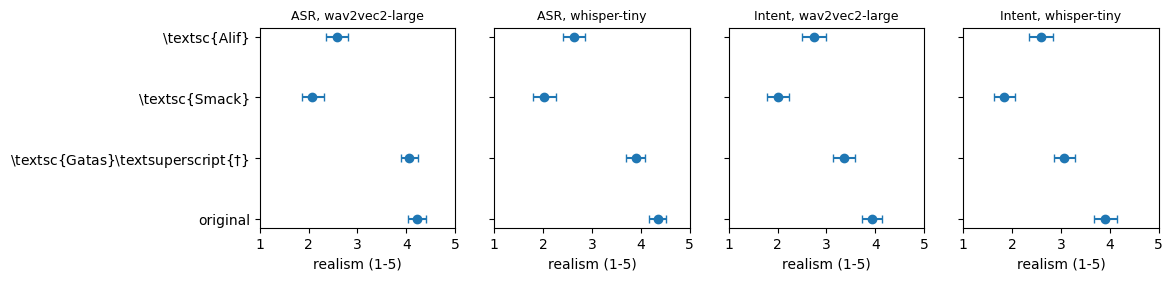

In [4]:
# human realism rating (1-5) per configuration (task x model) and method, mean with bootstrap 95% CI over the ratings
import matplotlib.pyplot as plt
from results_loader import tex_name

def boot_mean(x, n_boot=5000, seed=0):
    rng = np.random.default_rng(seed)
    return np.quantile([x[rng.integers(0, len(x), len(x))].mean() for _ in range(n_boot)], [0.025, 0.975])

R_ORDER = ["Clean", "GATAS", "GATAS_llm", "SMACK", "ALIF"]
rows = []
for (task, model, method), g in ok.groupby(["task", "model", "method"]):
    x = g.realism.to_numpy(float)
    lo, hi = boot_mean(x)
    rows.append({"task": task, "model": model, "method": method, "ratings": len(x), "mean": x.mean(), "CI low": lo, "CI high": hi})
mean_realism = pd.DataFrame(rows).sort_values(["task", "model", "method"], key=lambda s: s.map(R_ORDER.index) if s.name == "method" else s)
mean_realism.round(2).to_csv("_tables/rq3_human_realism_by_method.csv", index=False)
display(mean_realism.round(2))

configs = sorted({(t, m) for t, m in zip(mean_realism.task, mean_realism.model)}, key=lambda c: (c[0], c[1]))
fig, axes = plt.subplots(1, len(configs), figsize=(2.9 * len(configs), 2.6), sharex=True, sharey=True, squeeze=False)
for ax, (task, model) in zip(axes[0], configs):
    v = mean_realism[(mean_realism.task == task) & (mean_realism.model == model)].reset_index(drop=True)
    ax.errorbar(v["mean"], range(len(v)), xerr=[v["mean"] - v["CI low"], v["CI high"] - v["mean"]], fmt="o", capsize=3, color="tab:blue")
    ax.set_yticks(range(len(v))); ax.set_yticklabels(["original" if m == "Clean" else tex_name(m) for m in v.method]); ax.invert_yaxis()
    ax.set_xlim(1, 5); ax.set_title(f"{task}, {model}", fontsize=9); ax.set_xlabel("realism (1-5)")
plt.savefig("_figures/rq3_human_realism.pdf", bbox_inches="tight")


## Human validity


In [5]:
import matplotlib.pyplot as plt
from results_loader import tex_name

ORDER = ["Clean", "GATAS", "GATAS_llm", "SMACK", "ALIF"]
ANSWERS = ["yes", "unsure", "no"]
rows = []
for (task, method), g in ok.groupby(["task", "method"]):
    n, k = len(g), int((g.understood_match == "yes").sum())
    rows.append({"task": task, "method": method, "ratings": n,
                 **{a: 100 * (g.understood_match == a).mean() for a in ANSWERS},
                 "strict [%]": 100 * k / n,
                 "lenient [%]": 100 * (g.understood_match != "no").mean()})
validity = pd.DataFrame(rows).sort_values(["task", "method"], key=lambda s: s.map(ORDER.index) if s.name == "method" else s)
validity.round(1).to_csv("_tables/rq3_human_validity.csv", index=False)
display(validity.round(1))

,task,method,ratings,yes,unsure,no,strict [%],lenient [%]
1,ASR,Clean,232,98.3,0.9,0.9,98.3,99.1
2,ASR,GATAS,229,86.5,5.7,7.9,86.5,92.1
3,ASR,SMACK,229,23.6,8.3,68.1,23.6,31.9
0,ASR,ALIF,229,47.6,14.4,38.0,47.6,62.0
5,Intent,Clean,232,98.3,0.0,1.7,98.3,98.3
6,Intent,GATAS_llm,232,22.8,7.8,69.4,22.8,30.6
7,Intent,SMACK,232,19.8,9.9,70.3,19.8,29.7
4,Intent,ALIF,231,62.8,10.8,26.4,62.8,73.6


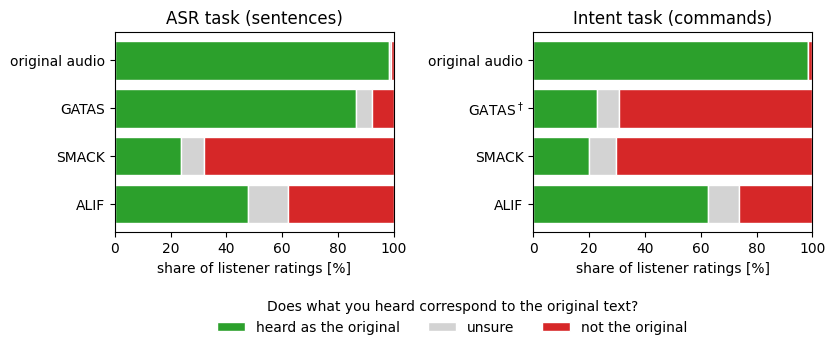

In [6]:
COLORS = {"yes": "tab:green", "unsure": "lightgray", "no": "tab:red"}
LEGEND = {"yes": "heard as the original", "unsure": "unsure", "no": "not the original"}
NAMES = {"Clean": "original audio", "GATAS": "GATAS", "GATAS_llm": "GATAS$^\\dagger$", "SMACK": "SMACK", "ALIF": "ALIF"}
fig, axes = plt.subplots(1, 2, figsize=(9, 2.6), sharex=True, gridspec_kw={"wspace": 0.5})
for ax, task, title in zip(axes, ("ASR", "Intent"), ("ASR task (sentences)", "Intent task (commands)")):
    v = validity[validity.task == task].reset_index(drop=True)
    left = np.zeros(len(v))
    for a in ANSWERS:
        ax.barh(range(len(v)), v[a], left=left, color=COLORS[a], label=LEGEND[a], edgecolor="white")
        left += v[a].to_numpy()
    ax.set_yticks(range(len(v))); ax.set_yticklabels([NAMES[m] for m in v.method]); ax.invert_yaxis()
    ax.set_xlim(0, 100); ax.set_xlabel("share of listener ratings [%]"); ax.set_title(title)
fig.legend(*axes[0].get_legend_handles_labels(), ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False,
           title="Does what you heard correspond to the original text?")
plt.savefig("_figures/rq3_human_validity.pdf", bbox_inches="tight")

In [7]:
from stats_utils import holm
BASE = ["SMACK", "ALIF"]
MEAS = {"realism": "Realism (1--5)", "heard": "Heard as the original [\\%]", "confirmed": "Human-confirmed success [\\%]"}

def cohen_d(x, y):
    sd = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(y) - 1) * y.var(ddof=1)) / (len(x) + len(y) - 2))
    return (x.mean() - y.mean()) / sd if sd > 0 else np.nan

rows = []
for (task, model), g in per_audio.groupby(["task", "model"]):
    ref = g[g.method == REF[task]]
    for meas in MEAS:
        scale = 1 if meas == "realism" else 100
        vals = {m: g[g.method == m][meas].to_numpy(float) for m in ["Clean", REF[task], *BASE]}
        ps = [stats.mannwhitneyu(vals[REF[task]], vals[b], alternative="greater").pvalue for b in BASE]
        ph = holm(ps)
        p_clean = stats.mannwhitneyu(vals[REF[task]], vals["Clean"], alternative="two-sided").pvalue
        for m, v in vals.items():
            row = {"task": task, "model": model, "measure": meas, "method": m, "audios": len(v), "value": scale * v.mean(),
                   "CI low": scale * np.quantile([v[rng.integers(0, len(v), len(v))].mean() for _ in range(2000)], 0.025),
                   "CI high": scale * np.quantile([v[rng.integers(0, len(v), len(v))].mean() for _ in range(2000)], 0.975)}
            if m in BASE:
                i = BASE.index(m)
                row.update({"p_holm": ph[i], "d": cohen_d(vals[REF[task]], v), "ref_better": bool(ph[i] < 0.05)})
            if m == REF[task]:
                row.update({"p_vs_clean": p_clean, "d_vs_clean": cohen_d(v, vals["Clean"])})
            rows.append(row)
tests = pd.DataFrame(rows)
tests.round(4).to_csv("_tables/rq3_human_tests.csv", index=False)
display(tests[tests.method != "Clean"].round(3).pivot_table(index=["measure", "task", "model"], columns="method", values=["value", "p_holm", "d"]).round(3))
print("reference vs original audio (two-sided, uncorrected):")
display(tests[tests.method.isin(REF.values())][["task", "model", "measure", "value", "p_vs_clean", "d_vs_clean"]].round(4))
print("reference significantly better than a baseline:", int(tests.ref_better.sum()), "of", int(tests.ref_better.notna().sum()))
print("effect sizes of the significant ones:", tests[tests.ref_better == True].d.pipe(lambda s: {"large": int((s > 1).sum()), "medium": int(((s > .5) & (s <= 1)).sum()), "small": int((s <= .5).sum())}))

import paper_tables as pt
CONF = [("whisper-tiny", "ASR"), ("whisper-tiny", "Intent"), ("wav2vec2-large", "ASR"), ("wav2vec2-large", "Intent")]
def tcell(meas, model, task, kind):
    method = "Clean" if kind == "Clean" else REF[task] if kind == "ours" else kind
    r = tests[(tests.measure == meas) & (tests.model == model) & (tests.task == task) & (tests.method == method)]
    if not len(r): return "--"
    r = r.iloc[0]
    text = f"{r.value:.2f}" if meas == "realism" else f"{r.value:.1f}"
    return text + (pt.bullet(r.d) if kind in BASE and r.ref_better else "")
lines = [r"\begin{table*}[t]", r"\caption{Human study (RQ\textsubscript{3}): mean over audios. Colored bullets indicate statistically significant differences relative to \tool in ASR and \gllm in intent matching, with colors representing effect sizes (\autoref{sec:metrics}).}",
         r"\label{tab:human}", r"\centering", r"\footnotesize", r"\adjustbox{max width=\textwidth}{%", r"\begin{tabular}{lcccc}\toprule",
         r" & \multicolumn{2}{c}{Whisper-tiny} & \multicolumn{2}{c}{wav2vec2-large} \\", r"\cmidrule(lr){2-3}\cmidrule(lr){4-5}",
         r" & ASR & Intent & ASR & Intent \\ \midrule"]
for meas, label in MEAS.items():
    lines.append(rf"\multicolumn{{5}}{{l}}{{\emph{{{label}}}}} \\")
    for kind, name in (("Clean", "Original audio"), ("ours", r"\tool / \gllm"), ("SMACK", r"\smack"), ("ALIF", r"\alif")):
        lines.append(f"{name} & " + " & ".join(tcell(meas, m, t, kind) for m, t in CONF) + r" \\")
    lines.append(r"\midrule" if meas != "confirmed" else "")
lines = [l for l in lines if l] + [r"\bottomrule", r"\end{tabular}}", r"\end{table*}"]
open("_tables/rq3_human.tex", "w").write("\n".join(lines) + "\n")
print("\n".join(lines))


d        p_holm          value          \
method                            ALIF  SMACK   ALIF  SMACK    ALIF   GATAS   
measure   task   model                                                        
confirmed ASR    wav2vec2-large  0.071  0.812  0.302  0.001  28.935  31.552   
                 whisper-tiny    0.609  1.246  0.009  0.000  25.631  48.422   
          Intent wav2vec2-large -1.351 -0.437  1.000  1.000  40.357     NaN   
                 whisper-tiny   -0.335  0.337  0.974  0.410  25.002     NaN   
heard     ASR    wav2vec2-large  1.342  1.648  0.000  0.000  41.890  87.096   
                 whisper-tiny    1.775  1.991  0.000  0.000  31.221  88.395   
          Intent wav2vec2-large -1.156  0.014  1.000  1.000  56.970     NaN   
                 whisper-tiny   -0.508  0.370  0.966  0.157  48.076     NaN   
realism   ASR    wav2vec2-large  2.117  2.597  0.000  0.000   2.268   3.984   
                 whisper-tiny    2.256  2.355  0.000  0.000   2.283   4.001   
          Intent wav2vec2-large  0.650  1.171  0.008  0.000   2.345     NaN   
                 whisper-tiny    0.883  1.418  0.000  0.000   2.224     NaN   

                                                   
method                          GATAS_llm   SMACK  
measure   task   model                             
confirmed ASR    wav2vec2-large       NaN   8.286  
                 whisper-tiny         NaN   8.452  
          Intent wav2vec2-large     1.395   5.263  
                 whisper-tiny      14.476   5.973  
heard     ASR    wav2vec2-large       NaN  31.784  
                 whisper-tiny         NaN  22.381  
          Intent wav2vec2-large    14.862  14.470  
                 whisper-tiny      28.023  15.618  
realism   ASR    wav2vec2-large       NaN   2.057  
                 whisper-tiny         NaN   2.003  
          Intent wav2vec2-large     2.979   1.925  
                 whisper-tiny       2.962   1.674

reference vs original audio (two-sided, uncorrected):


,task,model,measure,value,p_vs_clean,d_vs_clean
1,ASR,wav2vec2-large,realism,3.9839,0.0964,-0.4331
5,ASR,wav2vec2-large,heard,87.0962,0.0058,-0.6964
9,ASR,wav2vec2-large,confirmed,31.5524,0.0000,1.2306
13,ASR,whisper-tiny,realism,4.0008,0.0055,-0.7271
17,ASR,whisper-tiny,heard,88.3953,0.0414,-0.5688
21,ASR,whisper-tiny,confirmed,48.4219,0.0000,1.7150
25,Intent,wav2vec2-large,realism,2.9792,0.0000,-1.0641
29,Intent,wav2vec2-large,heard,14.8622,0.0000,-4.2359
33,Intent,wav2vec2-large,confirmed,1.3946,0.4130,-0.2925
37,Intent,whisper-tiny,realism,2.9619,0.0000,-1.2808


reference significantly better than a baseline: 15 of 24
effect sizes of the significant ones: {'large': 11, 'medium': 4, 'small': 0}
\begin{table*}[t]
\caption{Human study (RQ\textsubscript{3}): mean over audios. Colored bullets indicate statistically significant differences relative to \tool in ASR and \gllm in intent matching, with colors representing effect sizes (\autoref{sec:metrics}).}
\label{tab:human}
\centering
\footnotesize
\adjustbox{max width=\textwidth}{%
\begin{tabular}{lcccc}\toprule
 & \multicolumn{2}{c}{Whisper-tiny} & \multicolumn{2}{c}{wav2vec2-large} \\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}
 & ASR & Intent & ASR & Intent \\ \midrule
\multicolumn{5}{l}{\emph{Realism (1--5)}} \\
Original audio & 4.48 & 4.01 & 4.29 & 3.94 \\
\tool / \gllm & 4.00 & 2.96 & 3.98 & 2.98 \\
\smack & 2.00\,\textcolor{red!80!black}{$\bullet$} & 1.67\,\textcolor{red!80!black}{$\bullet$} & 2.06\,\textcolor{red!80!black}{$\bullet$} & 1.92\,\textcolor{red!80!black}{$\bullet$} \\
\alif & 2.28\,\te